# Question:
### A kicker has a historical field goal success rate of 80% ($p = 0.80$). During a season, he attempts 15 field goals ($n = 15$). Assuming each kick is independent, what is the probability that he successfully makes at least 12 of his 15 attempts?
# Description:
### The random variable we are simulating is 15 field goals. 
### One trial would be like: The kicker makes 9/15, which means he did not make at least 12/15.

In [158]:
import pandas as pd
import random
import math
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

# 1. Set parameters for one season
n_attempts = 15
p_success = 0.80

## Estimated Probability

In [159]:
# Create DataFrame for all possible outcomes (0 to 15 field goals)
df = pd.DataFrame({"Makes": range(n_attempts + 1)})

In [160]:
# Calculate binomial probability for each outcome
df["Probability"] = df["Makes"].apply(
    lambda k: math.comb(n_attempts, k) * (p_success**k) * ((1 - p_success) ** (n_attempts - k))
)

In [161]:
# Filter and sum for outcomes where Makes >= 12
prob_at_least_12 = df.loc[df["Makes"] >= 12, "Probability"].sum()

print(f"P(X >= 12) = {prob_at_least_12:.4f} (or {prob_at_least_12 * 100:.2f}%)")

P(X >= 12) = 0.6482 (or 64.82%)


# Actual Simulation

In [162]:
# 1. Create a pandas DataFrame containing all possible outcomes (0 to 12 returns)
df = pd.DataFrame({"X_returns": range(n_attempts + 1)})

In [163]:
# 2. Calculate the binomial probability for each outcome using math.comb:
# Formula: P(X) = nCr * (p^k) * ((1-p)^(n-k))
df["Probability"] = df["X_returns"].apply(
    lambda x: math.comb(n_attempts, x) * (p_success ** x) * ((1 - p_success) ** (n_attempts - x))
)

In [164]:
# 3. Filter for exactly 4 returned orders
prob_4 = df.loc[df["X_returns"] == 4, "Probability"].values[0]

print(f"P(X = 4) = {prob_4:.5f} (or {prob_4 * 100:.2f}%)\n")
print("Full Binomial Distribution Table:")
print(df.to_string(index=False))

P(X = 4) = 0.00001 (or 0.00%)

Full Binomial Distribution Table:
 X_returns  Probability
         0 3.276800e-11
         1 1.966080e-09
         2 5.505024e-08
         3 9.542042e-07
         4 1.145045e-05
         5 1.007640e-04
         6 6.717597e-04
         7 3.454764e-03
         8 1.381906e-02
         9 4.299262e-02
        10 1.031823e-01
        11 1.876042e-01
        12 2.501389e-01
        13 2.308974e-01
        14 1.319414e-01
        15 3.518437e-02


# Mean and Standard Deviation

In [165]:
# 1. Theoretical calculations using binomial formulas:
# Mean: mu = n * p
mean_theoretical = n_attempts * p_success

# Standard Deviation: sigma = sqrt(n * p * (1 - p))
std_theoretical = math.sqrt(n_attempts * p_success * (1 - p_success))

# 2. Calculation using the full probability distribution table in pandas:
df = pd.DataFrame({"Makes": range(n_attempts + 1)})
df["Probability"] = df["Makes"].apply(
    lambda k: math.comb(n_attempts, k) * (p_success**k) * ((1 - p_success) ** (n_attempts - k))
)

# Mean = sum(x * P(x))
mean_pandas = (df["Makes"] * df["Probability"]).sum()

# Standard Deviation = sqrt(sum((x - mean)^2 * P(x)))
variance_pandas = (
    ((df["Makes"] - mean_pandas) ** 2) * df["Probability"]
).sum()
std_pandas = math.sqrt(variance_pandas)

# Display results
print(f"Mean (Expected Makes): {mean_pandas:.2f} successful kicks")
print(f"Standard Deviation: {std_pandas:.4f} kicks")

Mean (Expected Makes): 12.00 successful kicks
Standard Deviation: 1.5492 kicks


# Theoretical and Emperical Probabilities

In [166]:
# Build the exact binomial probability distribution
df_theoretical = pd.DataFrame({"Makes": range(n_attempts + 1)})
df_theoretical["Probability"] = df_theoretical["Makes"].apply(
    lambda k: math.comb(n_attempts, k) * (p_success**k) * ((1 - p_success) ** (n_attempts - k))
)

In [167]:
# Sum probabilities for Makes >= 12
prob_theoretical = df_theoretical.loc[
    df_theoretical["Makes"] >= 12, "Probability"
].sum()

print(f"Theoretical Probability (P >= 12): {prob_theoretical:.4f} ({prob_theoretical * 100:.2f}%)")

Theoretical Probability (P >= 12): 0.6482 (64.82%)


In [168]:
outcomes = ["Made", "Missed"]
weights = [p_success, 1 - p_success]

# Simulate 1 season (15 independent kicks)
season_kicks = random.choices(outcomes, weights=weights, k=n_attempts)

In [169]:
# Create a DataFrame for the single season
df_season = pd.DataFrame(
    {
        "Attempt": [f"Kick {i+1}" for i in range(n_attempts)],
        "Outcome": season_kicks,
    }
)

print(df_season)

    Attempt Outcome
0    Kick 1    Made
1    Kick 2    Made
2    Kick 3  Missed
3    Kick 4    Made
4    Kick 5  Missed
5    Kick 6    Made
6    Kick 7    Made
7    Kick 8    Made
8    Kick 9    Made
9   Kick 10    Made
10  Kick 11  Missed
11  Kick 12    Made
12  Kick 13    Made
13  Kick 14    Made
14  Kick 15    Made


In [170]:
# Calculate empirical probability based on this single trial (1 season)
# Success condition: making at least 12 field goals
total_makes = (df_season["Outcome"] == "Made").sum()
met_target = total_makes >= 12

In [171]:
# For a single experiment (n=1 season), empirical probability is either 1.0 (Target Met) or 0.0 (Target Not Met)
empirical_prob = 1.0 if met_target else 0.0

print(f"Total Makes: {total_makes} / {n_attempts}")
print(f"Met Target (>= 12 Makes): {met_target}")
print(f"Empirical Probability: {empirical_prob:.2f} ({empirical_prob * 100:.0f}%)")

Total Makes: 12 / 15
Met Target (>= 12 Makes): True
Empirical Probability: 1.00 (100%)


# Graphs

In [172]:
plt.figure(figsize=(10, 6))
# Define bar colors based on whether the target (>= 12 makes) is met
colors = ["green" if k >= 12 else "skyblue" for k in df["Makes"]]

<Figure size 1000x600 with 0 Axes>

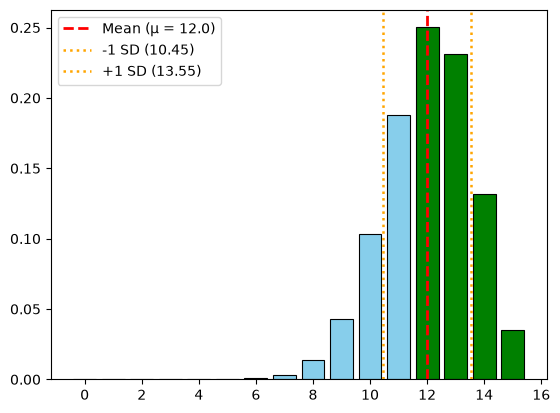

In [173]:
# Plot bars using Matplotlib directly
mean_val = 15 * 0.80  # mu = 12

bars = plt.bar(
    df["Makes"],
    df["Probability"],
    color=colors,
    edgecolor="black",
    linewidth=0.8,
)
plt.axvline(
    x=mean_val,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean (μ = {mean_val:.1f})",
)
# Standard Deviation Lines (±1 SD)
plt.axvline(
    x=mean_val - std_pandas,
    color="orange",
    linestyle=":",
    linewidth=1.8,
    label=f"-1 SD ({mean_val - std_pandas:.2f})",
)
plt.axvline(
    x=mean_val + std_pandas,
    color="orange",
    linestyle=":",
    linewidth=1.8,
    label=f"+1 SD ({mean_val + std_pandas:.2f})",
)
plt.legend(loc="upper left")

# Conclusion
## The Theoretical probability is around 64.82%. However, out of one season, the emperical probability is 1.00 (100%). We can see that the mean is 12 field goals made, which is 80% completed. 